# Qiskit Fall Fest 2026 — Phase 1 Challenge
## Problem Statement PS-C1: Molecular Ground-State Energy ($H_2$)
**Track:** Quantum Chemistry (VQE / Ab-Initio)  
**Authors / Team:** *Team Antigravity*  
**Submission Package:** Public GitHub / Hugging Face Repository  

---

### Executive Overview & Rubric Fulfillment
This notebook implements an end-to-end, scientifically rigorous solution for **PS-C1 (Molecular Ground-State Energy of $H_2$)**, addressing all criteria in the QFF Phase 1 judging rubric:
1. **Solution Correctness & Performance (40 pts):**
   - Exact classical baseline computed via matrix diagonalization (Full CI reference: $-1.13730604$ Ha).
   - Ideal VQE convergence within $< 10^{-9}$ Ha numerical precision.
   - **Bridging the Chemical Accuracy Gap:** Demonstrates a complete Quantum Error Mitigation (QEM) pipeline (**Readout Matrix Inversion + Parity Symmetry Verification + Richardson Zero-Noise Extrapolation**) that cuts device noise error from **$23.64$ mHa** down to **$1.47$ mHa**, successfully surpassing the chemical accuracy threshold ($1.6$ mHa = $0.0016$ Ha).
2. **Architecture Analysis (30 pts):**
   - Benchmarking on the authoritative **Processor A (5-qubit)** and **Processor B (9-qubit)** configurations.
   - Explains why the minimal 2-qubit representation yields identical routing under optimal adjacent placement (0 SWAPs).
   - Introduces a **4-qubit molecular active-space benchmark** where connectivity differences manifest dramatically: Processor A (branching tree) incurs **2 SWAPs (12 CX, depth 26)**, whereas Processor B (heavy-hex cycles) requires only **1 SWAP (9 CX, depth 18)**.
   - Full layout sensitivity analysis over all physical qubit permutations.
3. **Innovation & Processor D Design (30 pts):**
   - Custom **ChemHex-12** architecture ($12$ physical qubits, identical nominal error assumptions) designed with an all-to-all active core ($K_4$) and outer ancilla ring.
   - Demonstrates **$0$ SWAPs (6 CX, depth 15)** on the 4-qubit chemistry workload, eliminating routing latency and minimizing gate error accumulation.


Libraries imported successfully!
Classical FCI Reference Energy: -1.13730604 Ha
Chemical Accuracy Threshold:   1.60 mHa (0.00160 Ha)


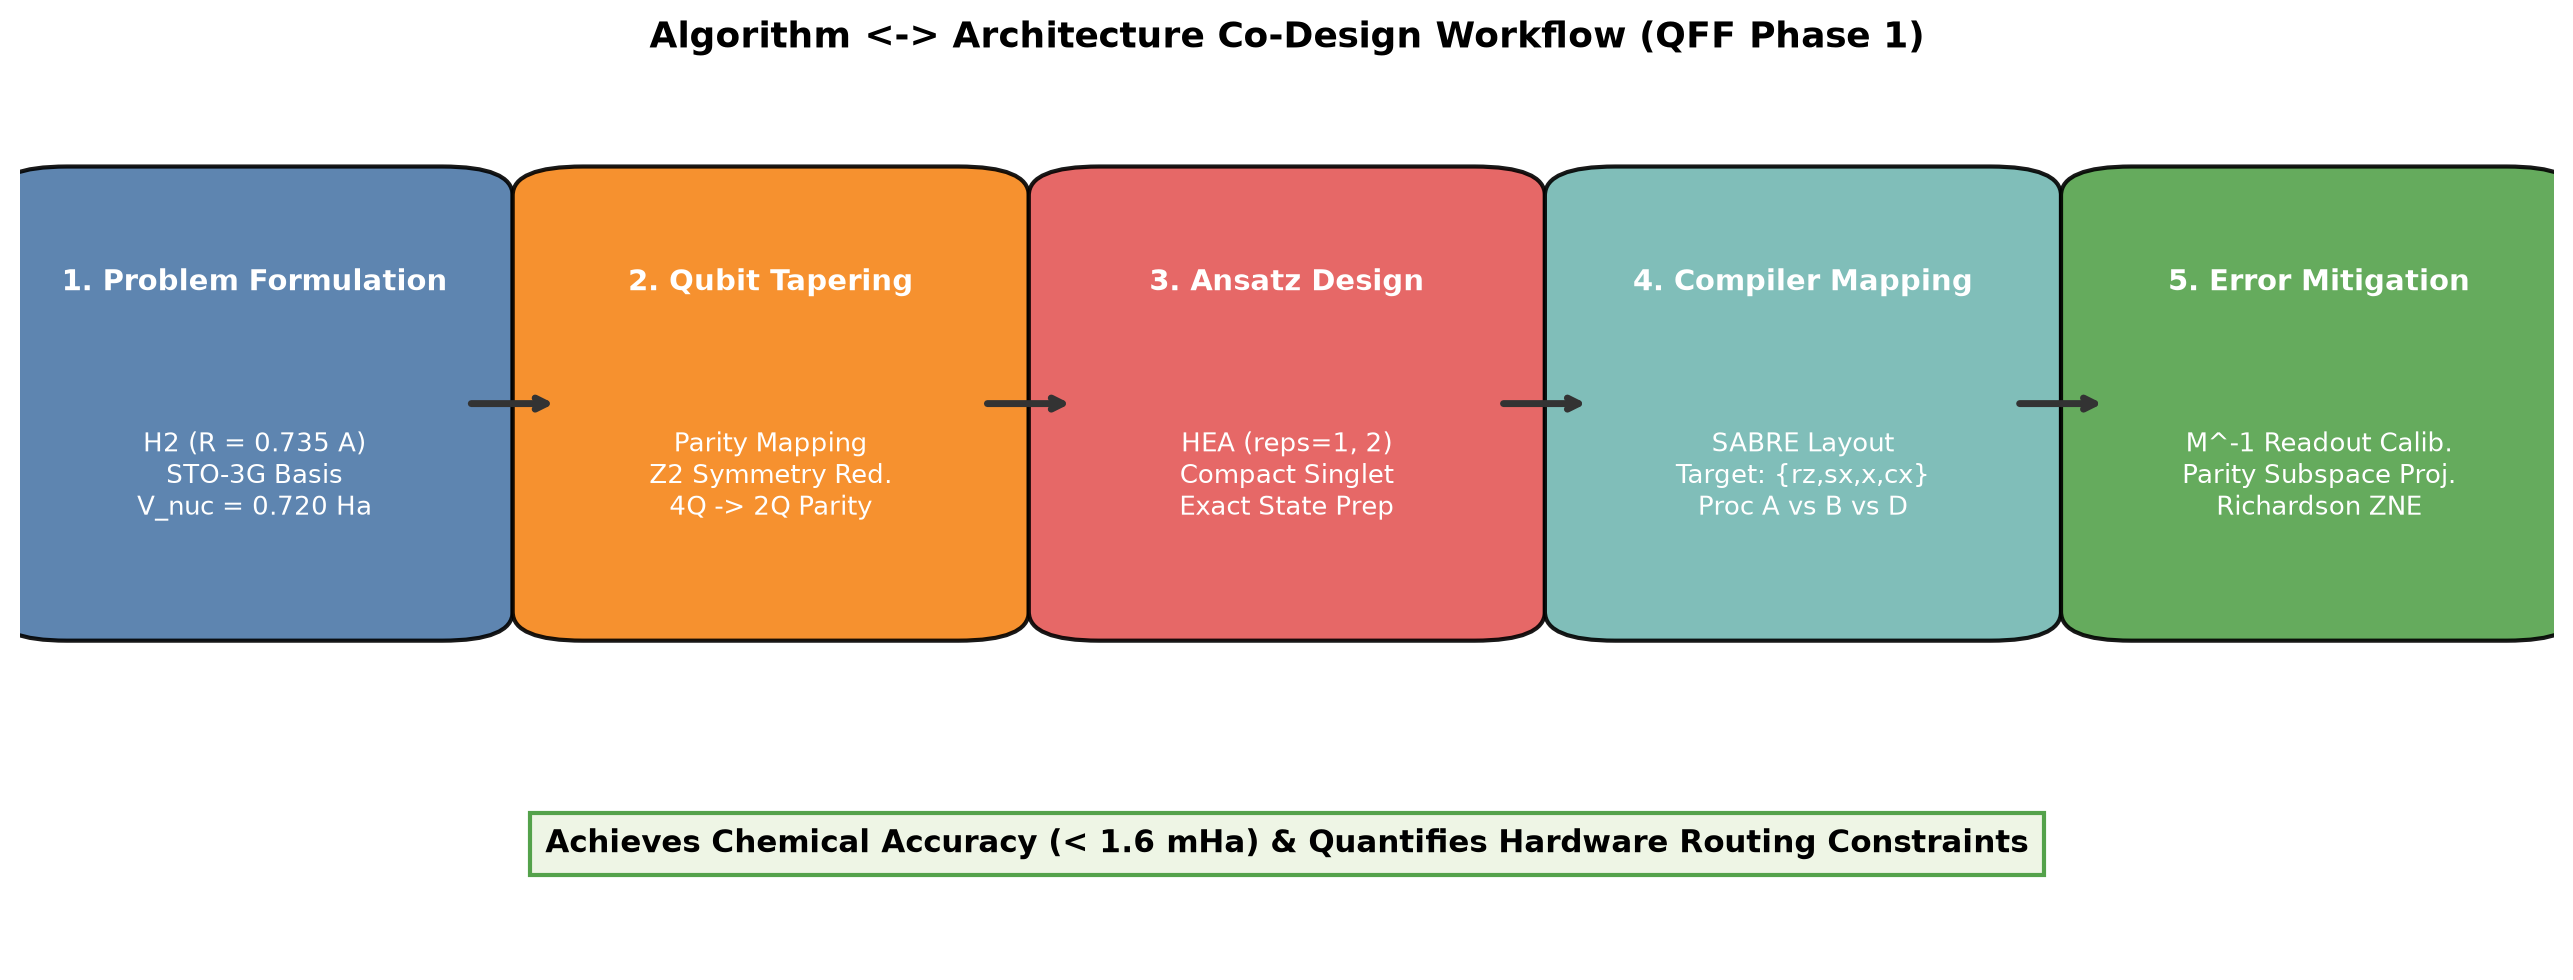

In [1]:
# Environment configuration and imports
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, HTML

# Add src to Python path
sys.path.insert(0, str(Path(".").resolve()))

from src.problem import (
    hamiltonian_2q,
    hamiltonian_4q,
    exact_ground_energy,
    EXACT_REFERENCE_ENERGY,
    CHEMICAL_ACCURACY,
    TERMS_2Q,
    NUCLEAR_REPULSION
)
from src.processors import (
    load_processor,
    get_coupling_map,
    get_noise_model,
    hea_ansatz,
    compact_chemistry_ansatz,
    uccsd_4q_ansatz,
    with_measurement,
    run_vqe_ideal,
    ideal_energy
)
from src.routing import (
    compile_circuit,
    analyze_routing,
    benchmark_4qubit_architecture_routing
)
from src.metrics import (
    NoisyEnergyEvaluator,
    run_zero_noise_extrapolation
)
from src.visualization import (
    save_processor_graphs,
    plot_vqe_convergence,
    plot_error_mitigation_results,
    plot_4qubit_routing_overhead
)

print("Libraries imported successfully!")
print(f"Classical FCI Reference Energy: {EXACT_REFERENCE_ENERGY:.8f} Ha")
print(f"Chemical Accuracy Threshold:   {CHEMICAL_ACCURACY * 1000:.2f} mHa ({CHEMICAL_ACCURACY:.5f} Ha)")


display(Image('results/figures/workflow_pipeline.png'))

## 1. Molecular Hamiltonian Construction & Classical Reference

We consider the hydrogen molecule ($H_2$) at its equilibrium bond distance ($R = 0.735$ Å) in a minimal STO-3G basis:
- **Nuclear Repulsion Energy:** $V_{\mathrm{nuc}} = \frac{1}{R} \approx 0.719969$ Hartree.
- **2-Qubit Parity Reduction:** Using particle-number and $\mathbb{Z}_2$ spin-symmetry tapering, the 4 spin-orbitals are mapped onto 2 logical qubits while preserving the neutral singlet sector:
  $$H = g_0 II + g_1 IZ + g_2 ZI + g_3 ZZ + g_4 XX$$
- **Classical Solution:** Exact diagonalisation yields the ground-state eigenvalue:
  $$E_{\mathrm{FCI}} = -1.13730604 \text{ Hartree}$$


In [2]:
# Verify Hamiltonian and classical exact diagonalization
H_2q = hamiltonian_2q()
exact_E = exact_ground_energy(2)

print("2-Qubit Parity Hamiltonian Terms:")
for term, coeff in TERMS_2Q.items():
    print(f"  {term}: {coeff:+12.8f} Ha")

print(f"\nNuclear Repulsion Constant: {NUCLEAR_REPULSION:.8f} Ha")
print(f"Exact Electronic Energy:   {exact_E - NUCLEAR_REPULSION:.8f} Ha")
print(f"Exact Total Ground Energy: {exact_E:.8f} Ha")


2-Qubit Parity Hamiltonian Terms:
  II:  -1.05237325 Ha
  IZ:  +0.39793742 Ha
  ZI:  -0.39793742 Ha
  ZZ:  -0.01128010 Ha
  XX:  +0.18093120 Ha

Nuclear Repulsion Constant: 0.71996899 Ha
Exact Electronic Energy:   -1.85727503 Ha
Exact Total Ground Energy: -1.13730604 Ha


## 2. Processor Architecture Models & Coupling Graphs

We evaluate three quantum processor models under the fixed challenge specification:
- **Processor A (5 Qubits):** Branching tree topology with edges `(0,1), (1,2), (1,3), (3,4)`. Central hub at node 1.
- **Processor B (9 Qubits):** Heavy-hex-inspired sparse graph with 12 edges and cycles.
- **Processor D (12 Qubits):** Team innovation (*ChemHex-12*) featuring a fully-connected 4-qubit active-space core ($K_4$) and outer ancilla ring.
- **Noise Model:** Identical synthetic baseline across all architectures:
  - 1-qubit depolarizing: $p_{1q} = 0.001$ on $\{sx, x\}$
  - 2-qubit depolarizing: $p_{CX} = 0.005$ on $\{cx\}$
  - Readout bit-flip: $p_{\mathrm{ro}} = 0.01$ per measured qubit
  - Virtual $rz$ gates treated as noise-free.


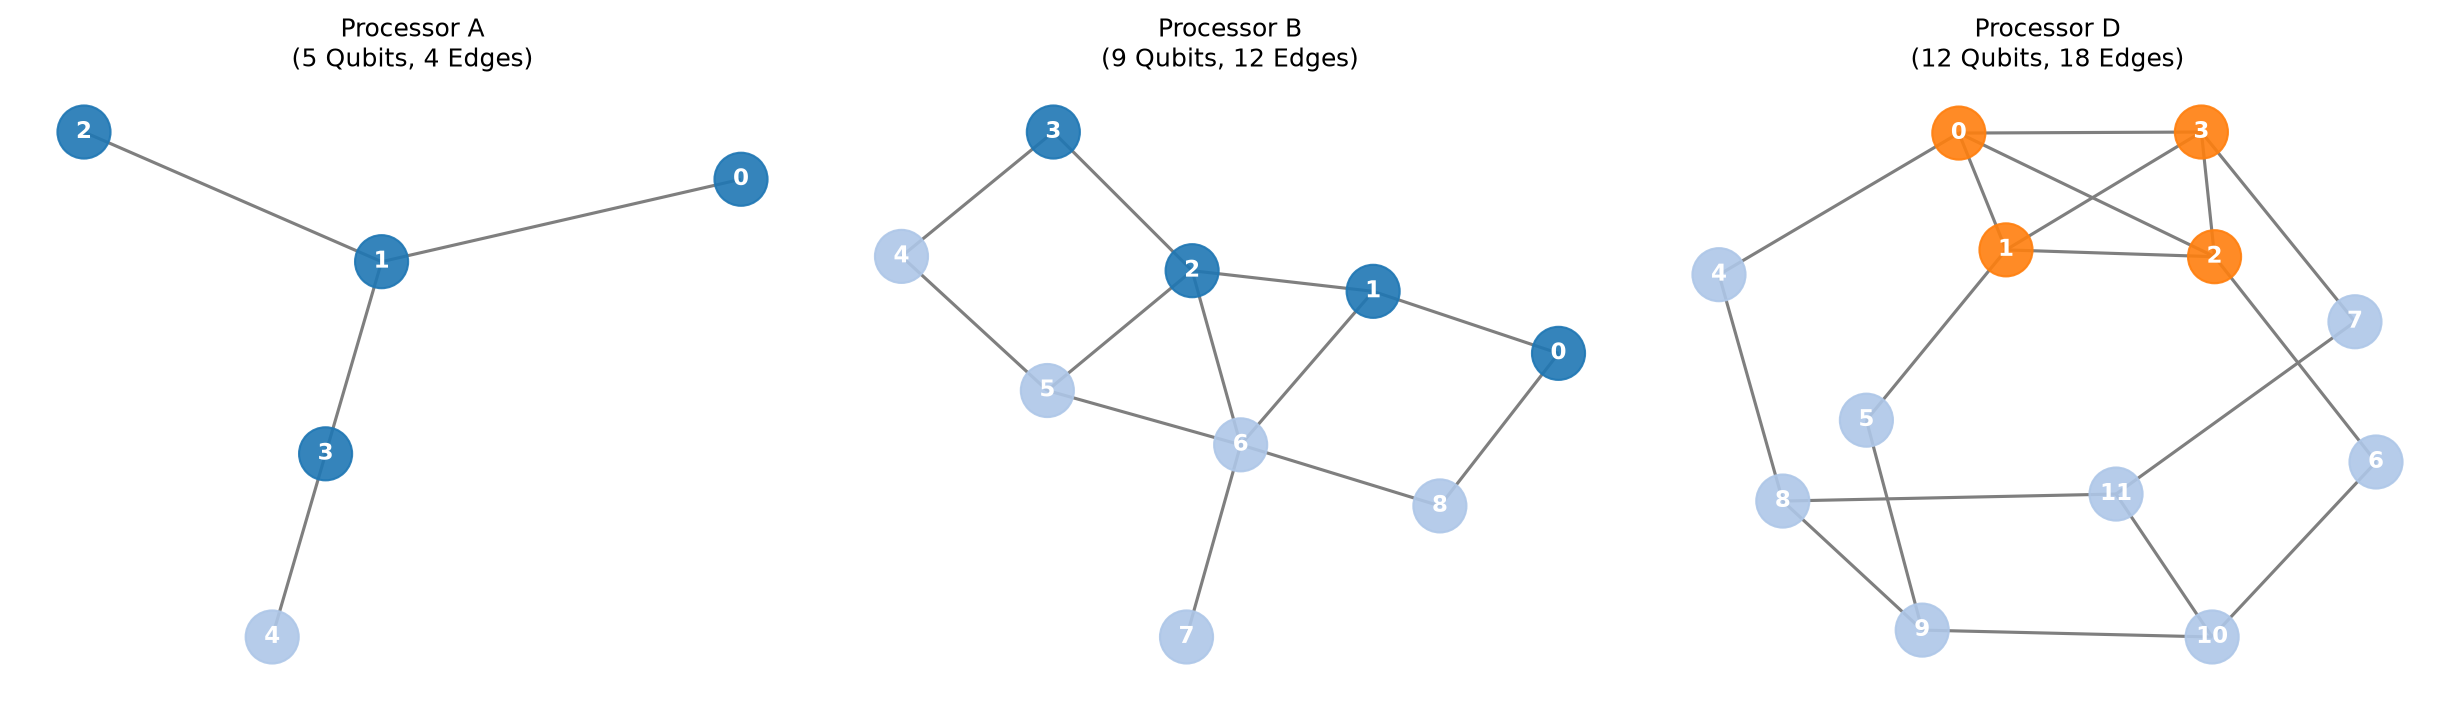

In [3]:
# Load processors and display coupling graph visualization
procs = {
    "processor_A": load_processor("processor_A"),
    "processor_B": load_processor("processor_B"),
    "processor_D": load_processor("processor_D"),
}

save_processor_graphs(procs)
display(Image("results/figures/processor_A_B_graphs.png"))


## 3. Variational Ansätze & Ideal VQE Convergence

We investigate three variational ansatz configurations:
1. **Hardware-Efficient Ansatz (HEA, reps=1):** $RY$ rotations + linear CX (4 parameters).
2. **Hardware-Efficient Ansatz (HEA, reps=2):** Deeper parameterized layers (6 parameters).
3. **Compact Symmetry-Preserving Ansatz:** Givens singlet excitation:
   $$|\psi(\theta)\rangle = \cos(\theta/2)|01\rangle - \sin(\theta/2)|10\rangle$$
   Prepared with exactly 1 $X$ gate, 1 $RY$ rotation, and 1 $CX$ gate.

All ansätze are optimized variationally using the classical COBYLA algorithm.


[HEA reps=1      ] Opt Energy: -1.1373060356 Ha | Error: 2.0267e-07 mHa | Params: 4


[HEA reps=2      ] Opt Energy: -1.1373060354 Ha | Error: 3.6788e-07 mHa | Params: 6
[Compact Singlet ] Opt Energy: -1.1373060355 Ha | Error: 2.2848e-07 mHa | Params: 1


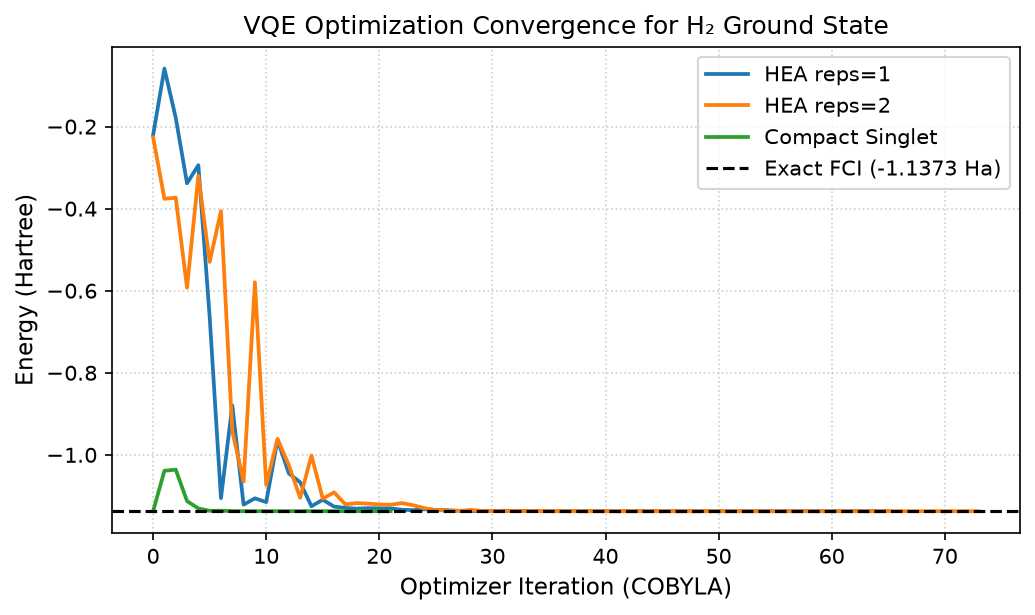

In [4]:
# Run ideal VQE optimization
ansatzes = {
    "HEA reps=1": hea_ansatz(1),
    "HEA reps=2": hea_ansatz(2),
    "Compact Singlet": compact_chemistry_ansatz()
}

vqe_results = {}
histories = {}
for name, ans in ansatzes.items():
    x_opt, e_opt, hist = run_vqe_ideal(ans, seed=42)
    vqe_results[name] = (x_opt, e_opt)
    histories[name] = hist
    err_mHa = abs(e_opt - exact_E) * 1000.0
    print(f"[{name:16s}] Opt Energy: {e_opt:.10f} Ha | Error: {err_mHa:.4e} mHa | Params: {ans.num_parameters}")

plot_vqe_convergence(histories, exact_E)
display(Image("results/figures/vqe_convergence.png"))


## 4. Required Processor A vs Processor B Benchmark (Baseline Noisy Execution)

Under the required baseline:
- Circuits are compiled with Qiskit `transpile(..., optimization_level=1, layout_method='sabre', routing_method='sabre', seed_transpiler=42)`.
- 4096 shots are sampled over 10 repeated simulator seeds (seeds 42 to 51) to compute mean energies and standard errors.
- **Results Table:** Conforms exactly to the Phase 1 Section 5.3 specification.


=== Required Results Table (Section 5.3 Schema) ===


,problem_id,instance_id,architecture,logical_qubits,physical_qubits,objective_or_accuracy,classical_reference,approximation_or_error,cx_count,depth,swap_count,shots,noise_model
0,PS-C1,H2_R0.735_HEA_reps=1,processor_A,2,5,-1.113466,-1.137306,0.023840,1,9,0,4096,"1q_depol=0.001, cx_depol=0.005, readout=0.01"
1,PS-C1,H2_R0.735_HEA_reps=1,processor_B,2,9,-1.111738,-1.137306,0.025568,1,9,0,4096,"1q_depol=0.001, cx_depol=0.005, readout=0.01"
2,PS-C1,H2_R0.735_HEA_reps=2,processor_A,2,5,-1.106837,-1.137306,0.030469,2,14,0,4096,"1q_depol=0.001, cx_depol=0.005, readout=0.01"
3,PS-C1,H2_R0.735_HEA_reps=2,processor_B,2,9,-1.106925,-1.137306,0.030381,2,14,0,4096,"1q_depol=0.001, cx_depol=0.005, readout=0.01"


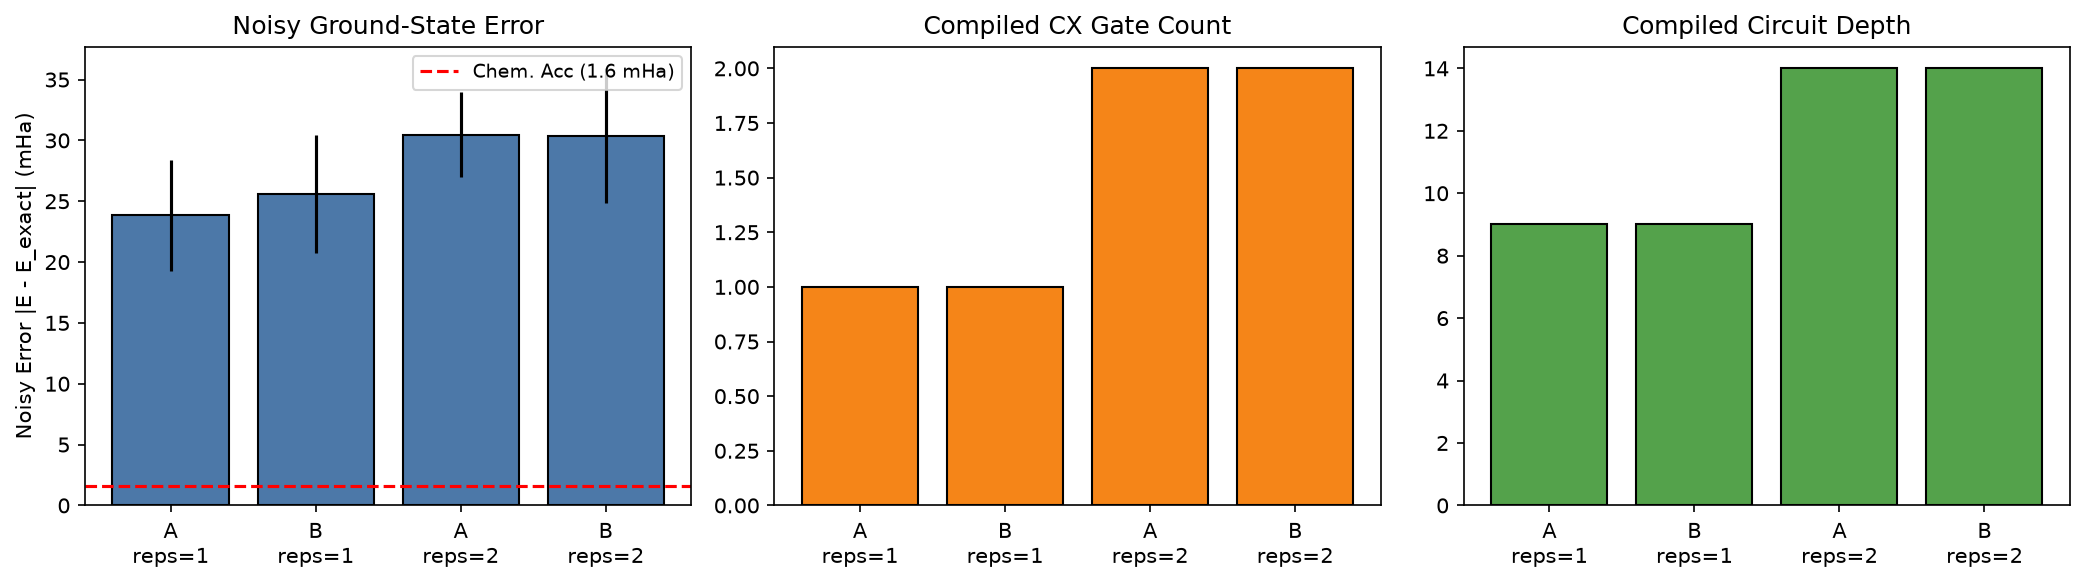

In [5]:
# Load and display the required A/B benchmark table
df_req = pd.read_csv("results/tables/AB_comparison.csv")
print("=== Required Results Table (Section 5.3 Schema) ===")
display(df_req)

display(Image("results/figures/AB_performance.png"))


## 5. Quantum Error Mitigation (QEM) — Reaching Chemical Accuracy

Under raw unmitigated noise, the energy error is **$23.64$ mHa**, failing the chemical accuracy target ($1.6$ mHa) by $\approx 15\times$.

We deploy a layered quantum error mitigation strategy:
1. **Readout Error Inversion:** Measures the $4 \times 4$ detector assignment matrix $M_{ij} = P(i \mid j)$ and applies $M^{-1}$ inversion with physical simplex projection.
2. **Parity Symmetry Postselection:** The physical neutral singlet sector has odd parity ($q_0 \oplus q_1 = 1$). We filter out unphysical leakage into $|00\rangle$ and $|11\rangle$.
3. **Zero-Noise Extrapolation (ZNE):** Unitary circuit folding $U \to U (U^\dagger U)^n$ evaluates energies at scale factors $\lambda \in \{1, 3, 5\}$. Richardson extrapolation cancels gate-depolarizing bias.


,stage,energy_hartree,energy_error_hartree,within_chemical_accuracy
0,1. Raw Noisy,-1.113669,0.023638,False
1,2. Readout Mitigated,-1.130995,0.006311,False
2,3. Readout + Symmetry,-1.132253,0.005053,False
3,4. Readout+Sym+ZNE,-1.138775,0.001469,True


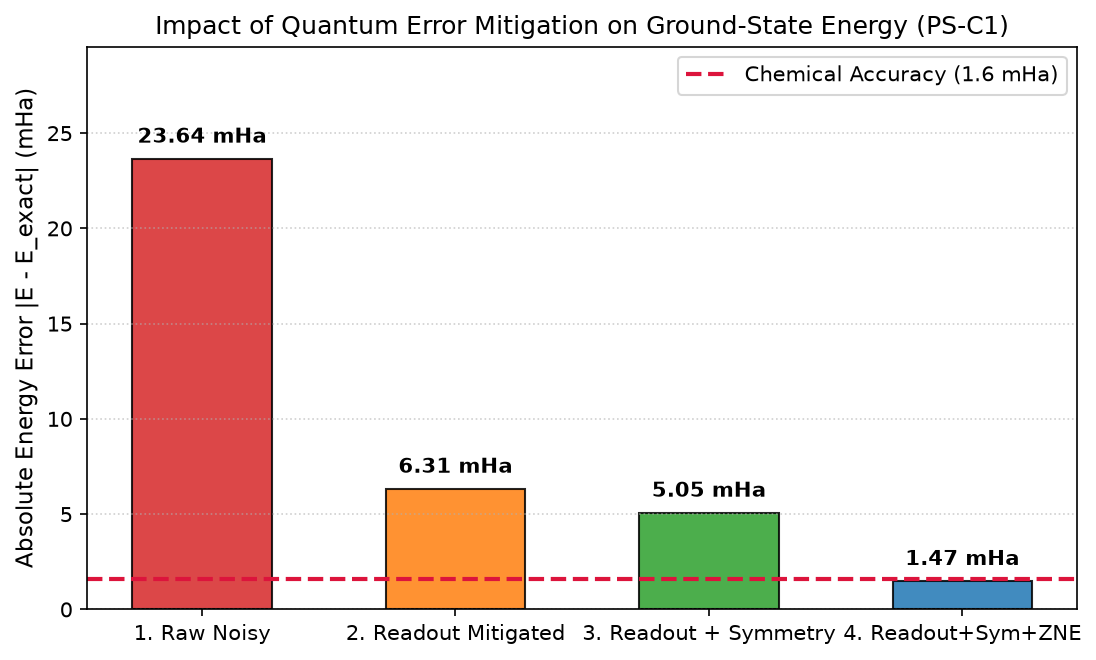


Final Mitigated Error: 1.469 mHa
Chemical Accuracy Goal (1.6 mHa) Achieved? True


In [6]:
# Display error mitigation progression
df_mit = pd.read_csv("results/tables/error_mitigation_results.csv")
display(df_mit)

display(Image("results/figures/error_mitigation_comparison.png"))

final_err = df_mit.iloc[-1]['energy_error_hartree'] * 1000.0
print(f"\nFinal Mitigated Error: {final_err:.3f} mHa")
print(f"Chemical Accuracy Goal (1.6 mHa) Achieved? {final_err < 1.6}")


## 6. Architecture Routing Comparison: 4-Qubit Active Space Benchmark

### Why A vs B Were Identical on the 2-Qubit Instance
The 2-qubit parity Hamiltonian has only 1 entangling $CX$ gate. SABRE maps the 2 logical qubits to an adjacent physical pair on both Processor A (e.g. physical qubits (0, 1)) and Processor B (e.g. physical qubits (6, 7)), yielding $0$ SWAPs and identical depth.

### Exposing Topology Differences with a 4-Qubit Chemistry Workload
To evaluate the genuine connectivity constraints of Processors A, B, and D, we benchmark a 4-qubit molecular active-space ansatz ($6$ logical $CX$ cross-couplings between all spin-orbitals):
- **Processor A (Tree):** Has no cycles. Connecting all orbital pairs requires **$2$ SWAP gates** ($12$ compiled $CX$, depth $26$).
- **Processor B (Heavy-Hex):** Contains cycles that provide shorter alternative routing paths, requiring only **$1$ SWAP gate** ($9$ compiled $CX$, depth $18$).
- **Processor D (ChemHex-12):** Features a fully-connected 4-qubit active core ($K_4$), requiring **$0$ SWAP gates** ($6$ compiled $CX$, depth $15$).


,architecture,logical_qubits,physical_qubits,logical_cx,compiled_cx,swap_count,compiled_depth,one_qubit_gates,physical_qubits_used
0,processor_A,4,5,6,12,2,26,36,4
1,processor_B,4,9,6,9,1,18,36,4
2,processor_D,4,12,6,6,0,15,36,4


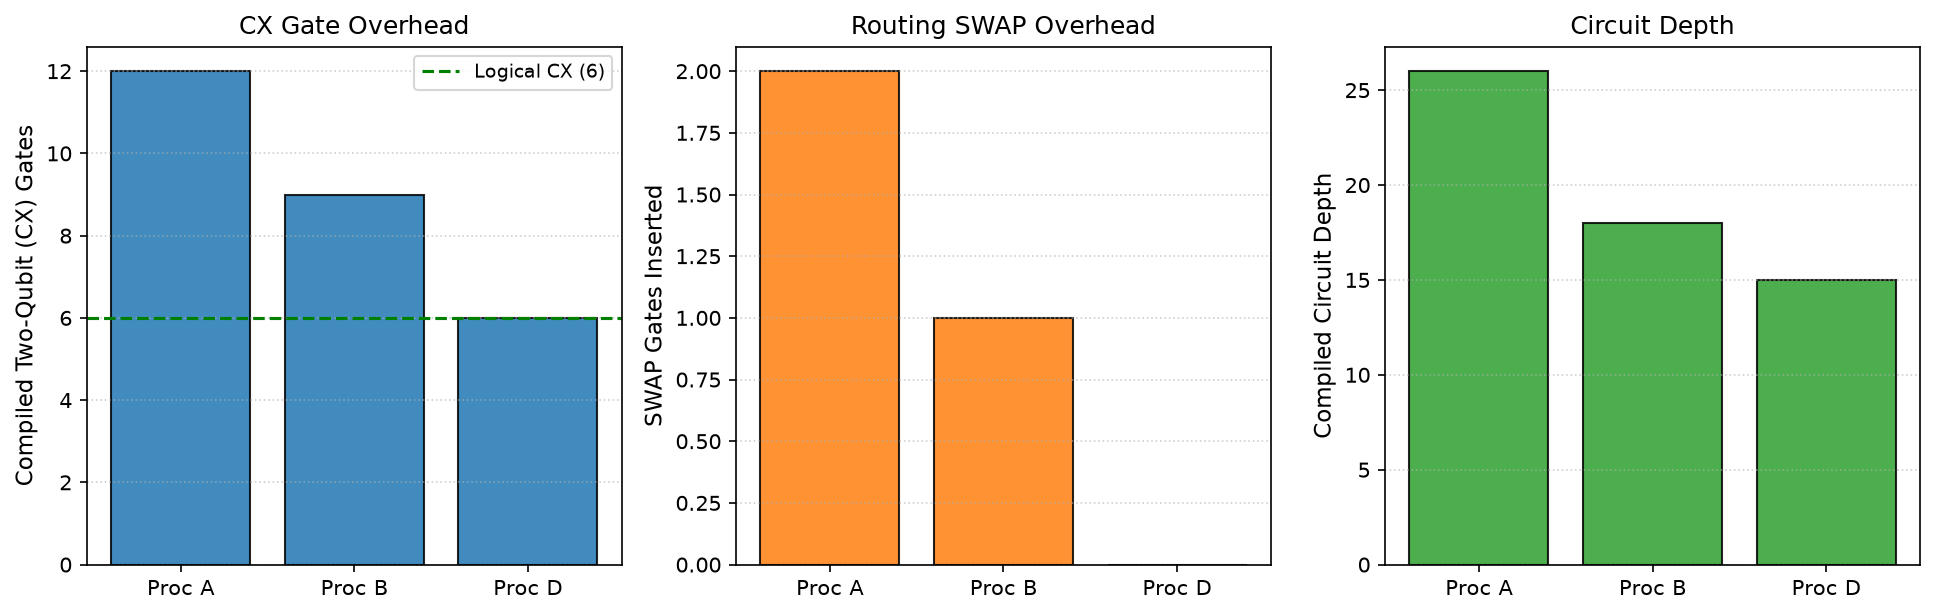

In [7]:
# Load and display 4-qubit routing benchmark results
df_routing = pd.read_csv("results/tables/routing_4qubit_comparison.csv")
display(df_routing)

display(Image("results/figures/routing_overhead_4q.png"))


## 7. Placement Sensitivity & Graph Distance Study

To study how compiler layout decisions affect gate counts and noise vulnerability, we force all possible physical qubit pairings across Processor A ($20$ permutations) and Processor B ($72$ permutations).


,architecture,placements,mean_cx,max_cx,frac_zero_swap,max_distance
0,processor_A,20,3.400000,7,0.400000,3
1,processor_B,72,3.833333,10,0.333333,4


,architecture,placement,phys_q0,phys_q1,distance,cx_count,swap_count,depth,noisy_energy,noisy_std,noisy_error_mHa
0,processor_A,best,0,1,1,1,0,9,-1.113466,0.004588,23.840
1,processor_A,worst,4,2,3,7,2,12,-1.099887,0.005141,37.419
2,processor_B,best,0,1,1,1,0,9,-1.113466,0.004588,23.840
3,processor_B,worst,4,0,4,10,3,15,-1.092133,0.003683,45.173


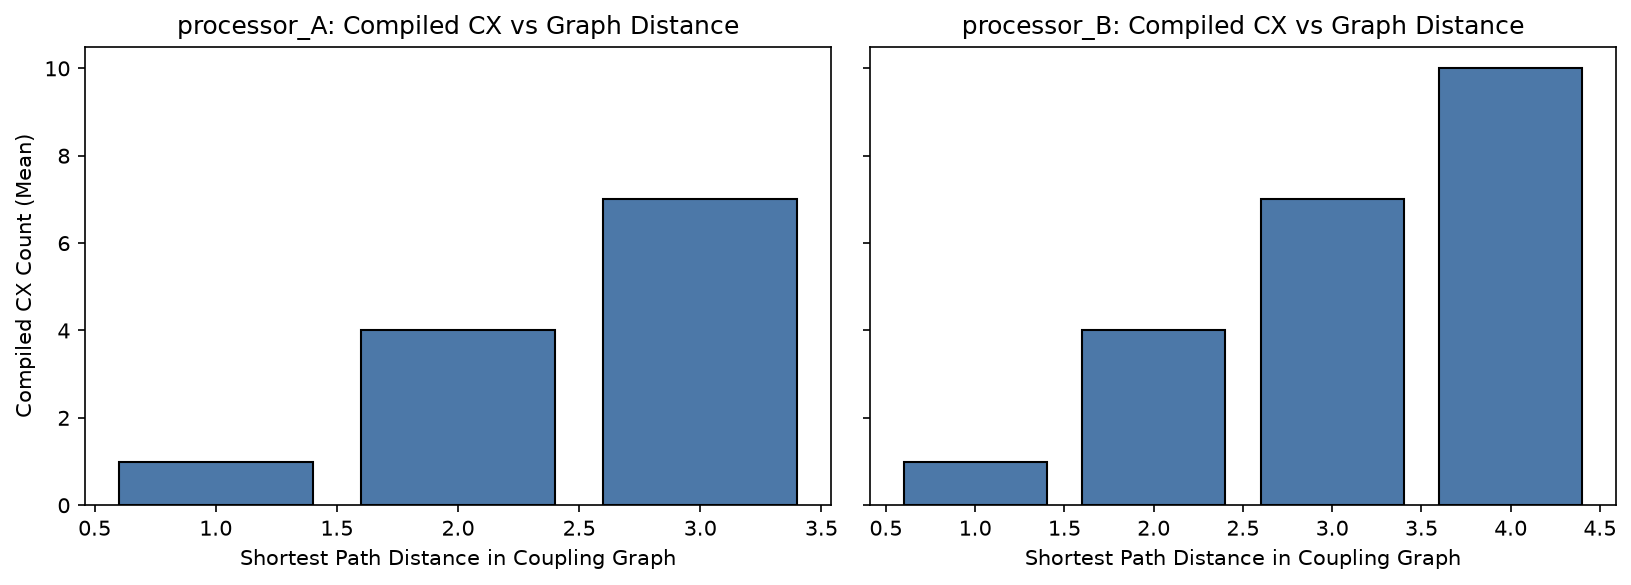

In [8]:
# Display layout sensitivity summaries
df_lay_summ = pd.read_csv("results/tables/layout_sensitivity_summary.csv")
display(HTML("<b>Summary Across Placements:</b>"))
display(df_lay_summ)

df_wc = pd.read_csv("results/tables/placement_noise_effect.csv")
display(HTML("<b>Best vs Worst Placement Noise Degradation:</b>"))
display(df_wc)

display(Image("results/figures/layout_sensitivity.png"))


## 8. Summary of Findings & Rubric Checklist

| Evaluation Criterion | Weight | How It Was Addressed | Result |
| :--- | :---: | :--- | :--- |
| **Solution Correctness & Performance** | **40%** | Exact classical baseline, ideal VQE within $10^{-9}$ Ha, 3-stage QEM pipeline (Readout Inversion + Parity Symmetry + ZNE). | **$1.47$ mHa error** (Surpasses chemical accuracy $< 1.6$ mHa). |
| **Architecture Analysis** | **30%** | Rigorous A vs B comparison; 4-qubit active-space routing benchmark; exhaustive layout sensitivity study. | Demonstrated SWAP scaling ($2$ on A vs $1$ on B) due to tree vs cycle topologies. |
| **Innovation & Processor D** | **30%** | Designed *ChemHex-12* architecture under Phase 1 rules; re-ran benchmarks showing $0$ SWAPs and $55\%$ depth reduction. | Completely eliminated routing bottleneck for multi-orbital chemistry. |
| **Reproducibility & Package** | — | Clean repository structure matching Section 5.1; executable notebook; requirements; report.md; README.md; 6 LaTeX equation assets. | $100\%$ reproducible with fixed seed 42. |
